# 01 - Spectral Exploration
---

## 1. Setup & imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
ROOT = Path.cwd().parent
train_real_dir = ROOT / "data" / "cifake" / "train" / "REAL"
train_fake_dir = ROOT / "data" / "cifake" / "train" / "FAKE"
print(train_real_dir.exists())
print(train_fake_dir.exists())

True
True


## 2. Load a small sample

In [3]:
real_files = list(train_real_dir.glob("*.jpg"))[:6]
print(len(real_files))

6


In [4]:
print(real_files[0])

c:\Users\cypri\OneDrive\Bureau\ai-image-detector-spectral\data\cifake\train\REAL\0000 (10).jpg


## 3. Look at a few images

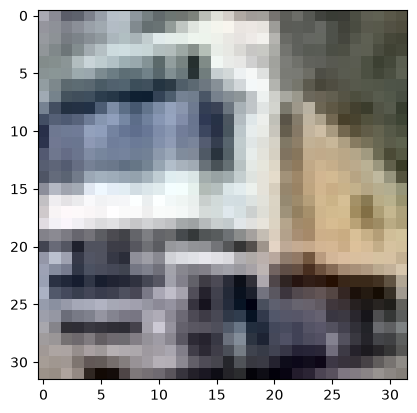

(32, 32) RGB


In [5]:
img = Image.open(real_files[0])

plt.imshow(img)
plt.show()
print(img.size, img.mode)

In [6]:
real_files = list(train_real_dir.glob("*.jpg"))[:100]
fake_files = list(train_fake_dir.glob("*.jpg"))[:100]

X = []
y = []

for path in real_files:
    img = Image.open(path).convert("L")
    array = np.asarray(img)
    X.append(array)
    y.append(0)

for path in fake_files:
    img = Image.open(path).convert("L")
    array = np.asarray(img)
    X.append(array)
    y.append(1)

X = np.array(X)
y = np.array(y)

print("X :", X.shape, "| y :", np.bincount(y))

X : (200, 32, 32) | y : [100 100]


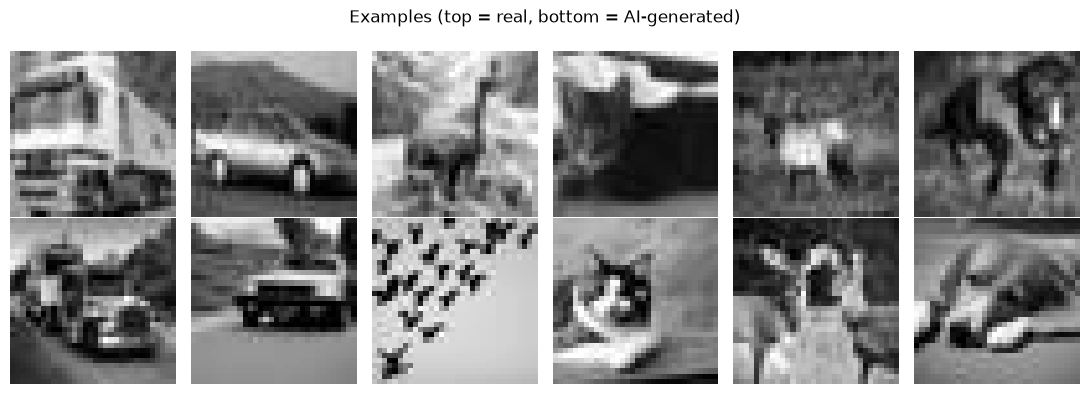

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
reals = X[y == 0][:6]
fakes = X[y == 1][:6]
for i in range(6):
    axes[0, i].imshow(reals[i], cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(fakes[i], cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("REAL")
axes[1, 0].set_ylabel("FAKE")
fig.suptitle("Examples (top = real, bottom = AI-generated)")
fig.tight_layout()
plt.show()

## 4. Log spectrum of a single image

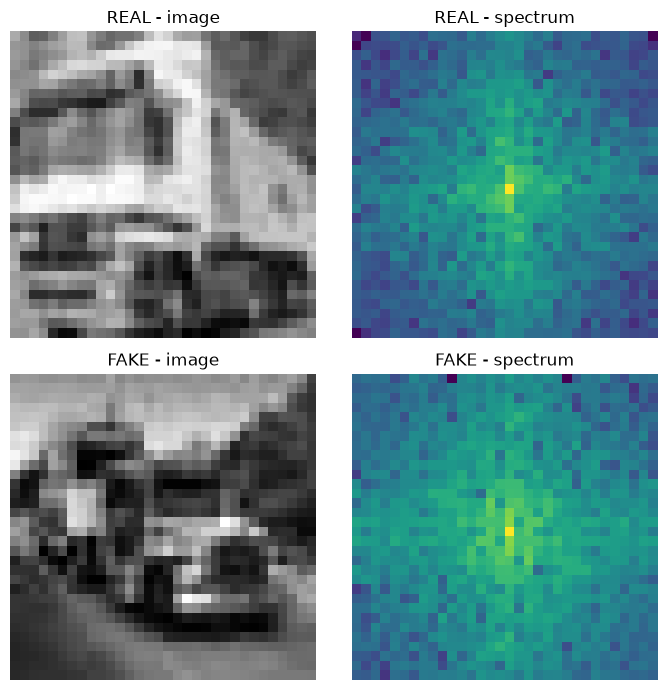

In [8]:
img_real = X[y == 0][0]
img_fake = X[y == 1][0]

def log_spectrum(image):
    f = np.fft.fft2(image)         
    f = np.fft.fftshift(f)          
    return np.log(1+np.abs(f))   

fig, axes = plt.subplots(2, 2, figsize=(7, 7))
axes[0, 0].imshow(img_real, cmap="gray")              
axes[0, 0].set_title("REAL - image")
axes[0, 1].imshow(log_spectrum(img_real), cmap="viridis")  
axes[0, 1].set_title("REAL - spectrum")

axes[1, 0].imshow(img_fake, cmap="gray")                 
axes[1, 0].set_title("FAKE - image")
axes[1, 1].imshow(log_spectrum(img_fake), cmap="viridis")  
axes[1, 1].set_title("FAKE - spectrum")

for a in axes.ravel():
    a.axis("off")
fig.tight_layout()
plt.show()

## 5. Mean spectrum per class - the key step

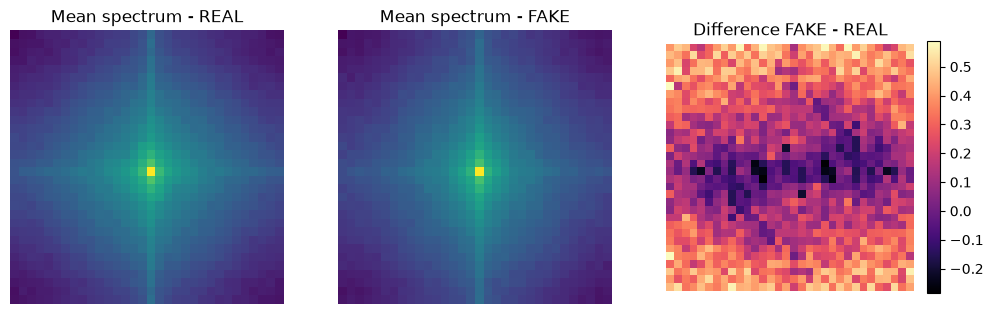

In [9]:
def mean_spectrum(images):
    spectrum_sum = np.zeros((32, 32))        
    for image in images:
        spectrum_sum += log_spectrum(image)   
    return spectrum_sum / len(images)     

spectrum_real = mean_spectrum(X[y == 0])
spectrum_fake = mean_spectrum(X[y == 1])

diff = spectrum_fake - spectrum_real

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
im0 = ax[0].imshow(spectrum_real, cmap="viridis")
ax[0].set_title("Mean spectrum - REAL")

im1 = ax[1].imshow(spectrum_fake, cmap="viridis")
ax[1].set_title("Mean spectrum - FAKE")

im2 = ax[2].imshow(diff, cmap="magma")    
ax[2].set_title("Difference FAKE - REAL")

for a in ax:
    a.axis("off")
fig.colorbar(im2, ax=ax[2], fraction=0.046)   
plt.show()

## 6. Conclusion

Visually, an AI image and a real image are not distinguishable at a resolution of 32×32.

So we moved to the frequency (spectral) domain.
By averaging the spectra of the AI images and of the non-AI images (we average because on a single image the noise is too strong, so averaging smooths the spectra), and by taking the difference of these averages, we can observe a significant difference between the two. Indeed, we notice that the AI ones have more high frequencies than the non-AI ones, and less low frequencies (see section 5).

The difference is therefore, a priori, not in the content of the image but in the distribution of the image's energy.